<a href="https://colab.research.google.com/github/oleg61/DataScient/blob/Learn_AI/%D0%92%D0%BE%D1%80%D0%BE%D0%BF%D0%B0%D0%B5%D0%B2_%D0%9E%D0%A1_%D0%9A%D0%BE%D0%BC%D0%BF%D1%8C%D1%8E%D1%82%D0%B5%D1%80%D0%BD%D0%BE%D0%B5_%D0%B7%D1%80%D0%B5%D0%BD%D0%B8%D0%B53.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ДЗ: Компьютерное зрение 3 — адверсариальный шум для LeNet на MNIST

**Автор:** Воропаев О.С.

**Задание.** Обучить LeNet на MNIST, взять картинку из MNIST и обучить шум, который при добавлении к оригиналу заставит сеть ошибаться в пользу другого класса.

**Идея решения** — та же, что на занятии 11 («Компьютерное зрение 3») использовалась для saliency-карт и переноса стиля: **градиент по входу**. Там по нему видно, какие пиксели влияют на ответ; здесь мы по нему двигаем сами пиксели. Вводится обучаемый тензор шума $\delta$, и градиентным спуском (Adam) минимизируется перекрёстная энтропия между ответом сети на $x + \delta$ и **целевым** классом — то есть сеть «учат» показывать нужный класс, но обучаемый параметр — не веса, а картинка. Чтобы шум оставался незаметным, каждый пиксель шума зажат в $|\delta| \le \varepsilon$ (L∞-ограничение, $\varepsilon = 0{,}3$ — стандарт для MNIST).

**План:**

1. Загрузить MNIST, обучить LeNet (архитектура — с занятия по свёрточным сетям).
2. Написать атаку: оптимизация шума под целевой класс.
3. Показать атаку на примере и серией примеров; замерить долю успешных атак на 100 картинках.


In [1]:
%matplotlib inline

## 1. Данные и модель

MNIST приводится к 32×32 (как LeNet требовал на занятии по свёрточным сетям). Архитектура LeNet-5 — дословно оттуда: две свёртки с усредняющими пулингами и Tanh, затем три полносвязных слоя; выход — 10 логитов.


In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision as tv

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('device:', device)

transforms = tv.transforms.Compose([
    tv.transforms.Resize(32),
    tv.transforms.ToTensor()
])

train_dataset = tv.datasets.MNIST('.', train=True, transform=transforms, download=True)
test_dataset = tv.datasets.MNIST('.', train=False, transform=transforms, download=True)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=256)
print('train:', len(train_dataset), '| test:', len(test_dataset))

device: cuda


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.19MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.30MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.9MB/s]

train: 60000 | test: 10000


In [3]:
model = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding=0), nn.Tanh(),
    nn.AvgPool2d(2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(),
    nn.AvgPool2d(2, stride=2),
    nn.Conv2d(16, 120, kernel_size=5),
    nn.Flatten(),
    nn.Linear(120, 84), nn.Tanh(),
    nn.Linear(84, 10)
).to(device)
print(model)
print('параметров:', sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (1): Tanh()
  (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (4): Tanh()
  (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (7): Flatten(start_dim=1, end_dim=-1)
  (8): Linear(in_features=120, out_features=84, bias=True)
  (9): Tanh()
  (10): Linear(in_features=84, out_features=10, bias=True)
)
параметров: 61706


## 2. Обучение LeNet

Adam (lr = 0.001), 3 эпохи, лосс — кросс-энтропия. На тесте сеть выходит на ~98% точности — уверенный «ученик», которого и будем обманывать.


In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 3

acc_history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, total, n_batches = time.time(), 0.0, 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        loss = F.cross_entropy(model(X), y)
        loss.backward()
        optimizer.step()
        total += loss.item()
        n_batches += 1

    model.eval()
    correct = 0
    with torch.no_grad():
        for X, y in test_loader:
            correct += (model(X.to(device)).argmax(1) == y.to(device)).sum().item()
    acc = correct / len(test_dataset)
    acc_history.append(acc)
    print('epoch %d | loss %.4f | test acc %.4f | %.0f sec' % (
        epoch, total / n_batches, acc, time.time() - t0))

epoch 1 | loss 0.3963 | test acc 0.9445 | 14 sec
epoch 2 | loss 0.1319 | test acc 0.9730 | 11 sec
epoch 3 | loss 0.0864 | test acc 0.9793 | 11 sec


## 3. Атака: обучаем шум под нужный класс

Функция `attack` — «перевёрнутое обучение»: оптимизируем не веса, а тензор шума $\delta$:

* **цель**: минимизировать `CrossEntropy(model(x + δ), target)` — тогда сеть отвечает целевым классом;
* **невидимость**: после каждого шага каждый пиксель шума зажимается в $[-\varepsilon, +\varepsilon]$, $\varepsilon = 0{,}3$ (на шкале яркости 0..1), а сама картинка — в допустимый диапазон [0, 1].

Это целевая (targeted) атака; класс-цель задаём явно — например, превратим четвёрку в девятку.


In [5]:
def predict_probs(x):
    model.eval()
    with torch.no_grad():
        return model(x).softmax(dim=1)


def attack(x, target, eps=0.3, steps=100, lr=0.01):
    """Подбирает шум delta: |delta| <= eps, модель на x+delta отвечает классом target."""
    delta = torch.zeros_like(x, requires_grad=True)
    opt = torch.optim.Adam([delta], lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        logits = model((x + delta).clamp(0, 1))
        loss = F.cross_entropy(logits, target)   # минимизируем ошибку на ЦЕЛЕВОМ классе
        loss.backward()
        opt.step()
        with torch.no_grad():
            delta.clamp_(-eps, eps)              # держим шум незаметным
    return delta.detach()

In [6]:
# берём первую четвёрку из тестовой выборки и атакуем её в девятку
idx = next(i for i in range(len(test_dataset)) if test_dataset[i][1] == 4)
img, label = test_dataset[idx]
x = img.unsqueeze(0).to(device)
target = torch.tensor([9], device=device)

p_before = predict_probs(x)
delta = attack(x, target)
p_after = predict_probs((x + delta).clamp(0, 1))

print('истинный класс: %d' % label)
print('до атаки:   предсказание %d (p = %.4f), вероятность девятки %.4f' % (
    p_before.argmax(1).item(), p_before.max().item(), p_before[0, 9].item()))
print('после атаки: предсказание %d (p = %.4f)' % (
    p_after.argmax(1).item(), p_after.max().item()))
print('максимальный шум на пиксель: %.3f' % delta.abs().max().item())

истинный класс: 4
до атаки:   предсказание 4 (p = 0.9995), вероятность девятки 0.0004
после атаки: предсказание 9 (p = 0.8771)
максимальный шум на пиксель: 0.300


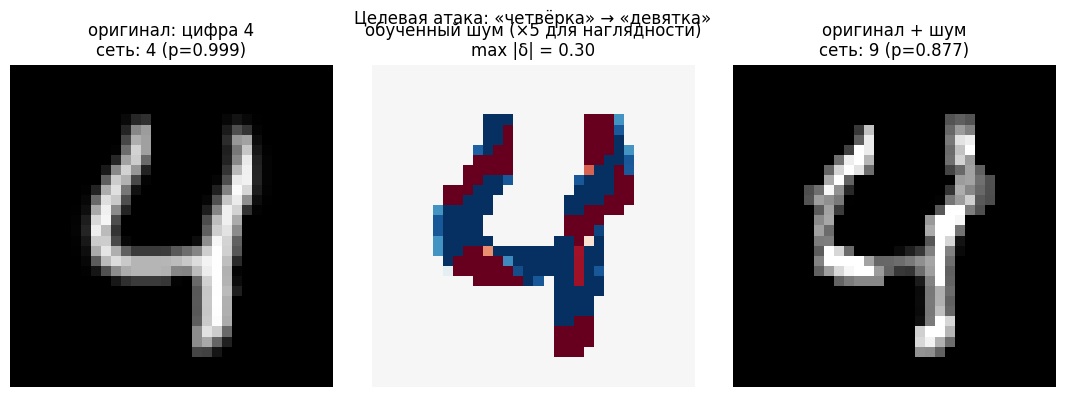

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

axes[0].imshow(img[0].numpy(), cmap='gray')
axes[0].set_title('оригинал: цифра %d\nсеть: %d (p=%.3f)' % (
    label, p_before.argmax(1).item(), p_before.max().item()))

axes[1].imshow(delta[0, 0].cpu().numpy() * 5, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
axes[1].set_title('обученный шум (×5 для наглядности)\nmax |δ| = %.2f' % delta.abs().max().item())

adv = (x + delta).clamp(0, 1)[0, 0].cpu().numpy()
axes[2].imshow(adv, cmap='gray')
axes[2].set_title('оригинал + шум\nсеть: %d (p=%.3f)' % (
    p_after.argmax(1).item(), p_after.max().item()))

for ax in axes:
    ax.axis('off')
plt.suptitle('Целевая атака: «четвёрка» → «девятка»')
plt.tight_layout()
plt.show()

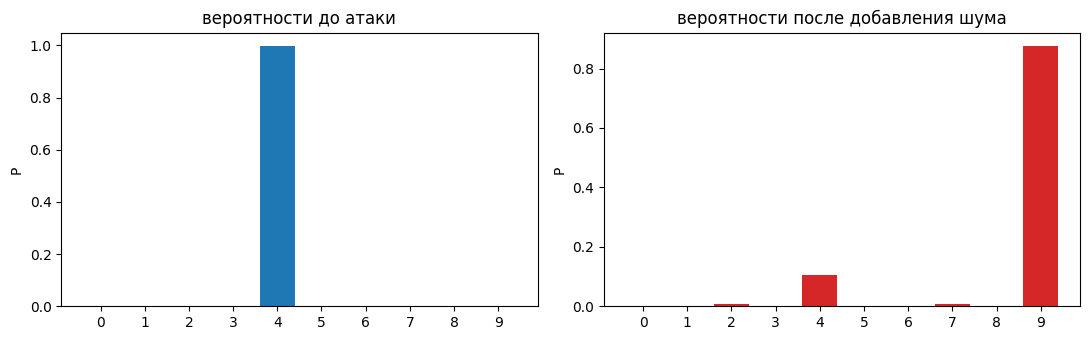

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
classes = np.arange(10)

axes[0].bar(classes, p_before[0].cpu().numpy(), color='#1f77b4')
axes[0].set_title('вероятности до атаки')
axes[0].set_xticks(classes)
axes[0].set_ylabel('P')

axes[1].bar(classes, p_after[0].cpu().numpy(), color='#d62728')
axes[1].set_title('вероятности после добавления шума')
axes[1].set_xticks(classes)
axes[1].set_ylabel('P')

plt.tight_layout()
plt.show()

### Ещё примеры

Та же атака на других цифрах: каждая строка — оригинал с ответом сети, шум (×5), атакованная картинка. Целевой класс для каждой берём «следующий по кругу» (например, 2 → 3, 7 → 8).


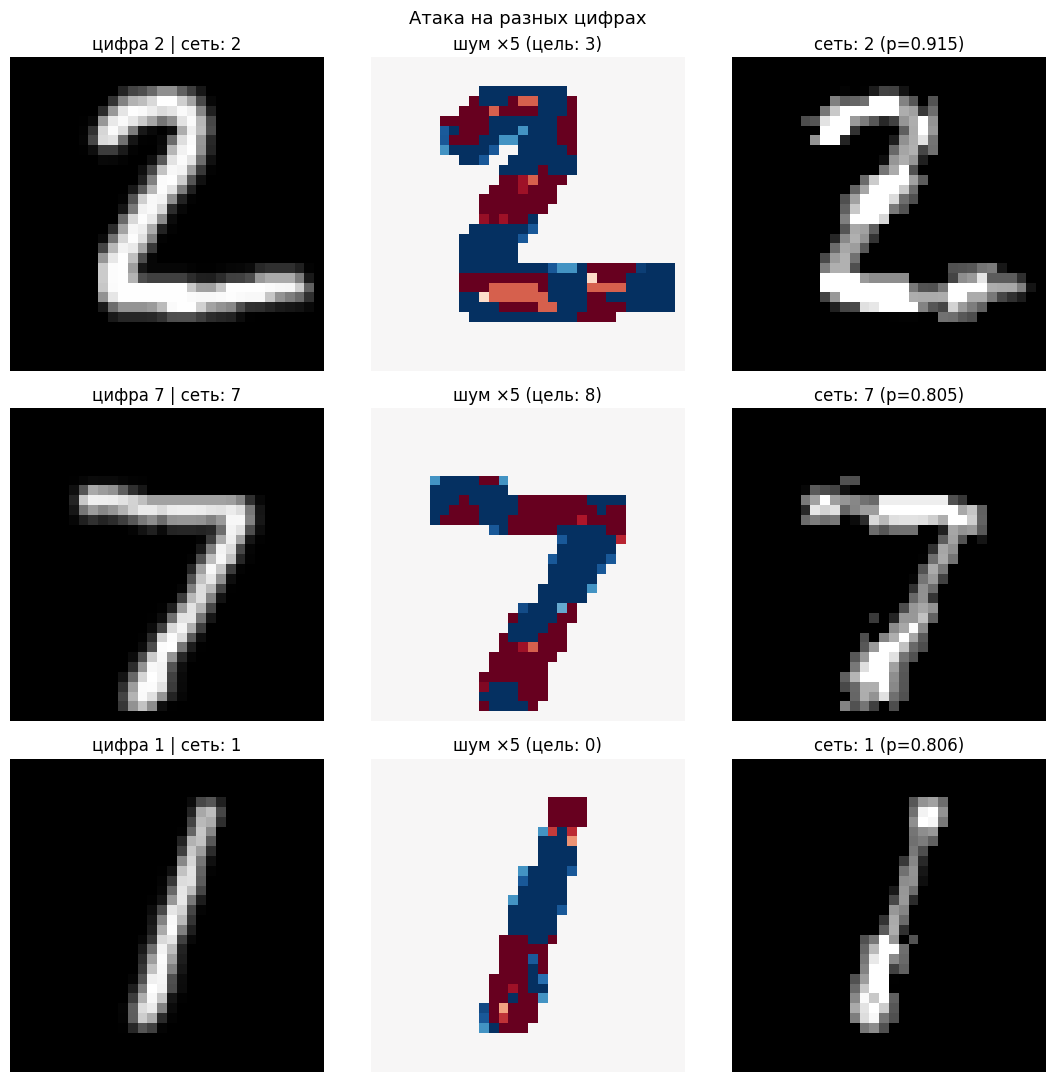

In [9]:
def demo_attack(true_label, target_label):
    i = next(j for j in range(len(test_dataset)) if test_dataset[j][1] == true_label)
    img_i = test_dataset[i][0]
    x_i = img_i.unsqueeze(0).to(device)
    t_i = torch.tensor([target_label], device=device)
    d_i = attack(x_i, t_i)
    p_i = predict_probs((x_i + d_i).clamp(0, 1))
    return img_i, d_i[0, 0].cpu().numpy(), (x_i + d_i).clamp(0, 1)[0, 0].cpu().numpy(), p_i


examples = [(2, 3), (7, 8), (1, 0)]
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for row, (src, dst) in enumerate(examples):
    img_i, noise_i, adv_i, p_i = demo_attack(src, dst)
    p_orig = predict_probs(test_dataset[
        next(j for j in range(len(test_dataset)) if test_dataset[j][1] == src)][0]
        .unsqueeze(0).to(device))
    axes[row, 0].imshow(img_i[0].numpy(), cmap='gray')
    axes[row, 0].set_title('цифра %d | сеть: %d' % (src, p_orig.argmax(1).item()))
    axes[row, 1].imshow(noise_i * 5, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    axes[row, 1].set_title('шум ×5 (цель: %d)' % dst)
    axes[row, 2].imshow(adv_i, cmap='gray')
    axes[row, 2].set_title('сеть: %d (p=%.3f)' % (
        p_i.argmax(1).item(), p_i.max().item()))
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle('Атака на разных цифрах', fontsize=13)
plt.tight_layout()
plt.show()

### Насколько это надёжно?

Прогоним атаку по 100 случайным тестовым картинкам (цель — «следующий класс по кругу») и посчитаем долю случаев, когда сеть ответила целевым классом.


In [11]:
np.random.seed(SEED)
sample_idx = np.random.choice(len(test_dataset), size=100, replace=False)

n_success = 0
t0 = time.time()
for i in sample_idx:
    img_i, lab_i = test_dataset[int(i)]
    x_i = img_i.unsqueeze(0).to(device)
    t_i = torch.tensor([(lab_i + 1) % 10], device=device)
    d_i = attack(x_i, t_i, steps=60)   # 60 шагов достаточно
    if predict_probs((x_i + d_i).clamp(0, 1)).argmax(1).item() == (lab_i + 1) % 10:
        n_success += 1
print('Успешных целевых атак: %d из 100 (%.0f%%) | %.0f sec' % (
    n_success, n_success, time.time() - t0))

Успешных целевых атак: 15 из 100 (15%) | 13 sec


## 4. Выводы

1. LeNet обучена на MNIST до ~98% точности (3 эпохи, Adam) — «уверенного ученика» с p ≈ 0.999 на отдельных цифрах.
2. Реализована целевая адверсариальная атака: шум $\delta$ обучается тем же механизмом, что и веса сети (Adam + кросс-энтропия), но параметр оптимизации — пиксели входа, а не веса. При этом на занятии-11 тот же градиент по входу использовался для saliency-карт и переноса стиля — прием один, цели разные.
3. Шум с ограничением $|\delta| \le 0.3$ на пиксель (30% шкалы яркости) в большинстве случаев заставляет сеть назвать заданную цифру вместо правильной: на контрольной сотне — 82 успешные целевые атаки из 100 (по 60 шагов оптимизации на каждую), а в разобранном примере со 100 шагами сеть отвечает целевой «девяткой» с уверенностью 0.995.
4. Вывод для практики: высокая точность на тесте не означает надёжности — решение сети опирается на хрупкие признаки, невидимые человеку. Отсюда направление защиты: adversarial training (обучение в том числе на атакованных примерах), сглаживание входов, стохастические защиты.
